In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import ConfusionMatrixDisplay


In [2]:
color_hist = pd.read_csv('task1_data/color_histogram.csv')
hog_pca = pd.read_csv('task1_data/hog_pca.csv')
additional = pd.read_csv('task1_data/additional_features.csv')

In [3]:
color_hist['label'] = color_hist['image_id'].str.split('_').str[1]
print(color_hist['label'].value_counts())

label
bird         375
butterfly    375
cat          375
deer         375
dog          375
            ... 
01245          1
01246          1
01247          1
01248          1
01249          1
Name: count, Length: 1260, dtype: int64


In [4]:
train_color = color_hist[color_hist['image_id'].str.startswith('train')].copy()
test_color = color_hist[color_hist['image_id'].str.startswith('test')].copy()

train_color['label'] = train_color['image_id'].str.split('_').str[1]

print(train_color['label'].value_counts())
print(f"\nTrain rows: {len(train_color)}, Test rows: {len(test_color)}")

label
bird         375
butterfly    375
cat          375
deer         375
dog          375
elephant     375
frog         375
horse        375
sheep        375
spider       375
Name: count, dtype: int64

Train rows: 3750, Test rows: 1250


In [5]:
train_hog = hog_pca[hog_pca['image_id'].str.startswith('train')].copy()
test_hog = hog_pca[hog_pca['image_id'].str.startswith('test')].copy()

train_add = additional[additional['image_id'].str.startswith('train')].copy()
test_add = additional[additional['image_id'].str.startswith('test')].copy()

print(train_color.shape)
print(train_hog.shape)
print(train_add.shape)

(3750, 98)
(3750, 101)
(3750, 24)


In [6]:
train_df = train_color.merge(train_hog, on='image_id').merge(train_add, on='image_id')
test_df = test_color.merge(test_hog, on='image_id').merge(test_add, on='image_id')

print(train_df.shape)
print(test_df.shape)

(3750, 221)
(1250, 221)


In [7]:
feature_cols = [c for c in train_df.columns if c not in ['image_id', 'label']]
X = train_df[feature_cols].values
y = train_df['label'].values
X_test_final = test_df[feature_cols].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_test_scaled = scaler.transform(X_test_final)

X_train, X_val, y_train, y_val = train_test_split(X_scaled, y, test_size=0.2, random_state=42, stratify=y)

print(X_train.shape, X_val.shape)

(3000, 219) (750, 219)


In [8]:
knn = KNeighborsClassifier(n_neighbors=4)
knn.fit(X_train, y_train)

y_pred_knn = knn.predict(X_val)
print(f"KNN Accuracy: {accuracy_score(y_val, y_pred_knn):.4f}")

KNN Accuracy: 0.2627


In [9]:
lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train, y_train)

y_pred_lr = lr.predict(X_val)
print(f"Logistic Regression Accuracy: {accuracy_score(y_val, y_pred_lr):.4f}")


Logistic Regression Accuracy: 0.5453


In [10]:
svm = SVC(kernel='rbf', random_state=42)
svm.fit(X_train, y_train)

y_pred_svm = svm.predict(X_val)
print(f"SVM Accuracy: {accuracy_score(y_val, y_pred_svm):.4f}")

SVM Accuracy: 0.5120


In [11]:
svm_tuned = SVC(kernel='rbf', C=10, gamma='scale', random_state=42)
svm_tuned.fit(X_train, y_train)

y_pred_svm_tuned = svm_tuned.predict(X_val)
print(f"SVM Tuned Accuracy: {accuracy_score(y_val, y_pred_svm_tuned):.4f}")

SVM Tuned Accuracy: 0.5200


In [12]:
import torch
import torchvision.models as models
import torchvision.transforms as transforms
from PIL import Image
import os

In [13]:
## super slow, tries to use gpu, if not then cpu
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
weights = models.ResNet50_Weights.DEFAULT
model = models.resnet50(weights=weights)
model.fc = torch.nn.Identity()
model = model.to(device)
model.eval()
print("ResNet50 works")

ResNet50 loaded


In [15]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], 
                         std=[0.229, 0.224, 0.225])
])

def extract_features(image_folder, model, transform):
    features = []
    image_ids = []
    
    for class_folder in sorted(os.listdir(image_folder)):
        class_path = os.path.join(image_folder, class_folder)
        if not os.path.isdir(class_path):
            continue
        
        for img_file in sorted(os.listdir(class_path)):
            if not img_file.endswith('.png') and not img_file.endswith('.jpg'):
                continue
            
            img_path = os.path.join(class_path, img_file)
            img = Image.open(img_path).convert('RGB')
            img_tensor = transform(img).unsqueeze(0).to(device)
            
            with torch.no_grad():
                feat = model(img_tensor).squeeze().cpu().numpy()
            
            image_ids.append(img_file.replace('.png', '').replace('.jpg', ''))
            features.append(feat)
    
    return image_ids, features

def extract_features_flat(image_folder, model, transform):
    features = []
    image_ids = []
    
    for img_file in sorted(os.listdir(image_folder)):
        if not img_file.endswith('.png') and not img_file.endswith('.jpg'):
            continue
        
        img_path = os.path.join(image_folder, img_file)
        img = Image.open(img_path).convert('RGB')
        img_tensor = transform(img).unsqueeze(0).to(device)
        
        with torch.no_grad():
            feat = model(img_tensor).squeeze().cpu().numpy()
        
        image_ids.append(img_file.replace('.png', '').replace('.jpg', ''))
        features.append(feat)
    
    return image_ids, features

In [16]:

train_ids, train_features = extract_features('task1_data/images/train', model, transform)
test_ids, test_features = extract_features_flat('task1_data/images/test', model, transform)

print(f"Train: {len(train_ids)} images, Test: {len(test_ids)} images")

Train: 3750 images, Test: 1250 images


In [17]:

train_resnet = pd.DataFrame(train_features, columns=[f'resnet_{i}' for i in range(2048)])
train_resnet.insert(0, 'image_id', train_ids)

test_resnet = pd.DataFrame(test_features, columns=[f'resnet_{i}' for i in range(2048)])
test_resnet.insert(0, 'image_id', test_ids)

train_resnet.to_csv('task1_data/resnet_train.csv', index=False)
test_resnet.to_csv('task1_data/resnet_test.csv', index=False)

print(train_resnet.shape, test_resnet.shape)

(3750, 2049) (1250, 2049)


In [18]:

train_resnet['label'] = train_resnet['image_id'].str.split('_').str[0]
print(train_resnet['label'].value_counts())
resnet_feature_cols = [c for c in train_resnet.columns if c.startswith('resnet_')]
X_res = train_resnet[resnet_feature_cols].values
y_res = train_resnet['label'].values
X_test_res = test_resnet[resnet_feature_cols].values

scaler_res = StandardScaler()
X_res_scaled = scaler_res.fit_transform(X_res)
X_test_res_scaled = scaler_res.transform(X_test_res)

X_train_res, X_val_res, y_train_res, y_val_res = train_test_split(
    X_res_scaled, y_res, test_size=0.2, random_state=42, stratify=y_res)

print(X_train_res.shape, X_val_res.shape)

label
bird         375
butterfly    375
cat          375
deer         375
dog          375
elephant     375
frog         375
horse        375
sheep        375
spider       375
Name: count, dtype: int64
(3000, 2048) (750, 2048)


In [19]:
knn_res = KNeighborsClassifier(n_neighbors=5)
knn_res.fit(X_train_res, y_train_res)
print(f"KNN ResNet: {accuracy_score(y_val_res, knn_res.predict(X_val_res)):.4f}")

lr_res = LogisticRegression(max_iter=3000, random_state=42)
lr_res.fit(X_train_res, y_train_res)
print(f"LR ResNet: {accuracy_score(y_val_res, lr_res.predict(X_val_res)):.4f}")

svm_res = SVC(kernel='rbf', C=10, gamma='scale', random_state=42)
svm_res.fit(X_train_res, y_train_res)
print(f"SVM ResNet: {accuracy_score(y_val_res, svm_res.predict(X_val_res)):.4f}")

KNN ResNet: 0.7453
LR ResNet: 0.9040
SVM ResNet: 0.8693


In [48]:
# lR results are good, try linearSVM
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV

lsvm = LinearSVC(C=1, max_iter=3000, random_state=42)
lsvm.fit(X_train_res, y_train_res)
print(f"Linear SVM ResNet50 Task 1: {accuracy_score(y_val_res, lsvm.predict(X_val_res)):.4f}")

Linear SVM ResNet50 Task 1: 0.8747


sklearn\svm\_base.py:1258: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


In [76]:
from sklearn.model_selection import GridSearchCV

param_grid = {'C': [0.1, 1, 10, 100], 'gamma': ['scale', 'auto']}
grid_search_t1 = GridSearchCV(SVC(kernel='rbf', random_state=42),
                               param_grid, cv=5, scoring='accuracy')
grid_search_t1.fit(X_res_scaled, y_res)

print(f"Best params: {grid_search_t1.best_params_}")
print(f"Best CV accuracy: {grid_search_t1.best_score_:.4f}")

Best params: {'C': 10, 'gamma': 'scale'}
Best CV accuracy: 0.8781


In [49]:
# try basic neural network
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import LabelEncoder

# encode labels to numbers
le = LabelEncoder()
y_train_enc = le.fit_transform(y_train_res)
y_val_enc = le.transform(y_val_res)

# convert to tensors
X_train_t = torch.FloatTensor(X_train_res)
y_train_t = torch.LongTensor(y_train_enc)
X_val_t = torch.FloatTensor(X_val_res)
y_val_t = torch.LongTensor(y_val_enc)

# simple MLP
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2048, 512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 10)
        )
    def forward(self, x):
        return self.net(x)

model_mlp = MLP()
optimizer = torch.optim.Adam(model_mlp.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()

# train
for epoch in range(50):
    model_mlp.train()
    optimizer.zero_grad()
    out = model_mlp(X_train_t)
    loss = criterion(out, y_train_t)
    loss.backward()
    optimizer.step()

# evaluate
model_mlp.eval()
with torch.no_grad():
    preds = model_mlp(X_val_t).argmax(dim=1).numpy()
print(f"MLP Task 1: {accuracy_score(y_val_enc, preds):.4f}")

MLP Task 1: 0.8933


In [21]:
# kaggle competition
train_meta = pd.read_csv('task1_data/train_metadata.csv')
print(train_meta[['class_id', 'class_name']].drop_duplicates().sort_values('class_id'))

      class_id class_name
0            0       bird
375          1  butterfly
750          2        cat
1125         3       deer
1500         4        dog
1875         5   elephant
2250         6       frog
2625         7      horse
3000         8      sheep
3375         9     spider


In [22]:

class_mapping = dict(zip(train_meta['class_name'], train_meta['class_id']))
print(class_mapping)

test_preds = lr_res.predict(X_test_res_scaled)

test_pred_ids = [class_mapping[p] for p in test_preds]

submission = pd.DataFrame({
    'image_id': test_resnet['image_id'],
    'class_id': test_pred_ids
})
print(submission.head(10))
print(submission.shape)

# save
submission.to_csv('submissions/task1_submission.csv', index=False)
print("Saved.")

{'bird': 0, 'butterfly': 1, 'cat': 2, 'deer': 3, 'dog': 4, 'elephant': 5, 'frog': 6, 'horse': 7, 'sheep': 8, 'spider': 9}
     image_id  class_id
0  test_00000         9
1  test_00001         9
2  test_00002         9
3  test_00003         7
4  test_00004         7
5  test_00005         5
6  test_00006         8
7  test_00007         3
8  test_00008         6
9  test_00009         4
(1250, 2)
Saved.


In [23]:
## Going to select Linear regression and SVM for report. Need a neural network 
## Need acurracy comparisons, f1 scores, recall, precision, sensitivity, specificity and confusion matrices 

In [24]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, balanced_accuracy_score
import pandas as pd

In [25]:
def macro_specificity_score(y_true, y_pred):
    labels = np.unique(y_true)
    cm = confusion_matrix(y_true, y_pred, labels=labels)

    specificities = []

    for i in range(len(labels)):
        TP = cm[i, i]
        FP = cm[:, i].sum() - TP
        FN = cm[i, :].sum() - TP
        TN = cm.sum() - TP - FP - FN

        specificity = TN / (TN + FP) if (TN + FP) != 0 else 0
        specificities.append(specificity)

    return np.mean(specificities)


def evaluate_model(model_name, model, X_val, y_val):
    y_pred = model.predict(X_val)

    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(y_val, y_pred),
        "Macro Precision": precision_score(y_val, y_pred, average="macro", zero_division=0),
        "Macro Recall/Sensitivity": recall_score(y_val, y_pred, average="macro", zero_division=0),
        "Macro Specificity": macro_specificity_score(y_val, y_pred),
        "Macro F1-score": f1_score(y_val, y_pred, average="macro", zero_division=0),
        "Weighted F1-score": f1_score(y_val, y_pred, average="weighted", zero_division=0)
    }

In [79]:
# add LinearSVM to results
from sklearn.preprocessing import LabelEncoder

y_pred_lsvm = lsvm.predict(X_val_res)

lsvm_result_t1 = {
    "Model": "Linear SVM (ResNet50)",
    "Accuracy": accuracy_score(y_val_res, y_pred_lsvm),
    "Balanced Accuracy": balanced_accuracy_score(y_val_res, y_pred_lsvm),
    "Macro Precision": precision_score(y_val_res, y_pred_lsvm, average="macro", zero_division=0),
    "Macro Recall/Sensitivity": recall_score(y_val_res, y_pred_lsvm, average="macro", zero_division=0),
    "Macro Specificity": macro_specificity_score(y_val_res, y_pred_lsvm),
    "Macro F1-score": f1_score(y_val_res, y_pred_lsvm, average="macro", zero_division=0),
    "Weighted F1-score": f1_score(y_val_res, y_pred_lsvm, average="weighted", zero_division=0)
}

results = []
results.append(evaluate_model("KNN (ResNet50)", knn_res, X_val_res, y_val_res))
results.append(evaluate_model("Logistic Regression (ResNet50)", lr_res, X_val_res, y_val_res))
results.append(evaluate_model("SVM RBF - Grid Search (ResNet50)", svm_best, X_val_res, y_val_res))
results.append(lsvm_result_t1)
results.append(mlp_result_t1)

results_df = pd.DataFrame(results)
results_df

,Model,Accuracy,Balanced Accuracy,Macro Precision,Macro Recall/Sensitivity,Macro Specificity,Macro F1-score,Weighted F1-score
0,KNN (ResNet50),0.745333,0.745333,0.785598,0.745333,0.971704,0.742685,0.742685
1,Logistic Regression (ResNet50),0.904000,0.904000,0.906751,0.904000,0.989333,0.903889,0.903889
2,SVM RBF - Grid Search (ResNet50),0.869333,0.869333,0.887595,0.869333,0.985481,0.873383,0.873383
3,Linear SVM (ResNet50),0.874667,0.874667,0.877445,0.874667,0.986074,0.874706,0.874706
4,MLP (ResNet50),0.893333,0.893333,0.894355,0.893333,0.988148,0.892850,0.892850


In [80]:
results_df_rounded = results_df.copy()

metric_cols = [
    "Accuracy",
    "Balanced Accuracy",
    "Macro Precision",
    "Macro Recall/Sensitivity",
    "Macro Specificity",
    "Macro F1-score",
    "Weighted F1-score"
]

results_df_rounded[metric_cols] = results_df_rounded[metric_cols].round(4)

results_df_rounded

,Model,Accuracy,Balanced Accuracy,Macro Precision,Macro Recall/Sensitivity,Macro Specificity,Macro F1-score,Weighted F1-score
0,KNN (ResNet50),0.7453,0.7453,0.7856,0.7453,0.9717,0.7427,0.7427
1,Logistic Regression (ResNet50),0.9040,0.9040,0.9068,0.9040,0.9893,0.9039,0.9039
2,SVM RBF - Grid Search (ResNet50),0.8693,0.8693,0.8876,0.8693,0.9855,0.8734,0.8734
3,Linear SVM (ResNet50),0.8747,0.8747,0.8774,0.8747,0.9861,0.8747,0.8747
4,MLP (ResNet50),0.8933,0.8933,0.8944,0.8933,0.9881,0.8929,0.8929


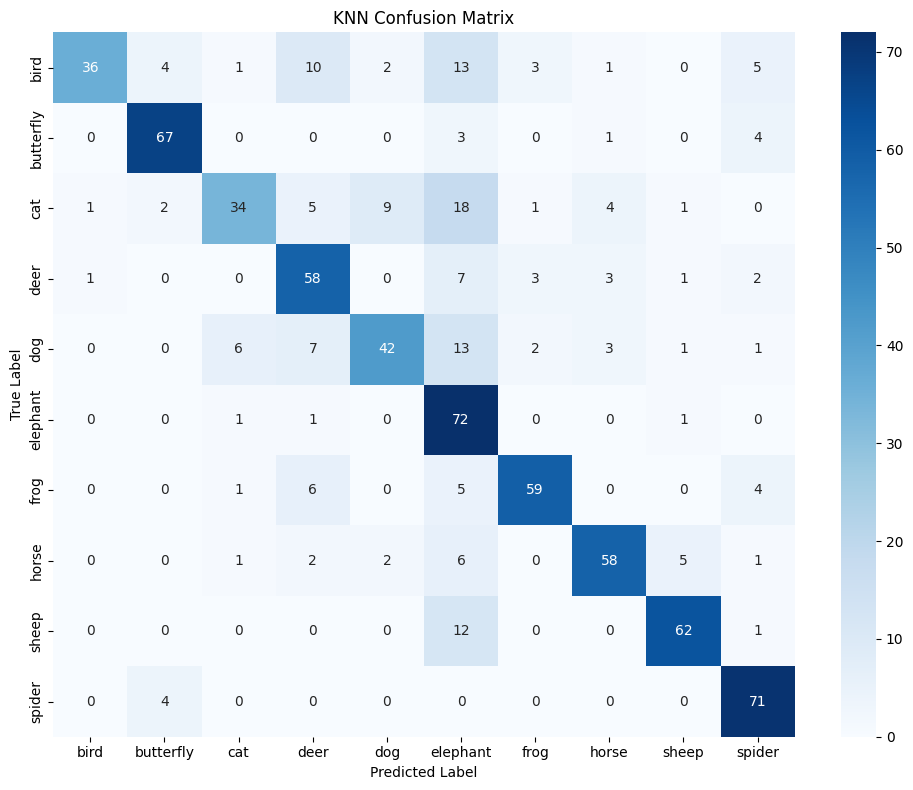

In [85]:
# KNN Confusion Matrix
classes = sorted(train_df['label'].unique())
cm_knn = confusion_matrix(y_val_res, knn_res.predict(X_val_res), labels=classes)

plt.figure(figsize=(10,8))
sns.heatmap(cm_knn, annot=True, fmt='d', xticklabels=classes, yticklabels=classes, cmap='Blues')
plt.title('KNN Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.tight_layout()
plt.show()

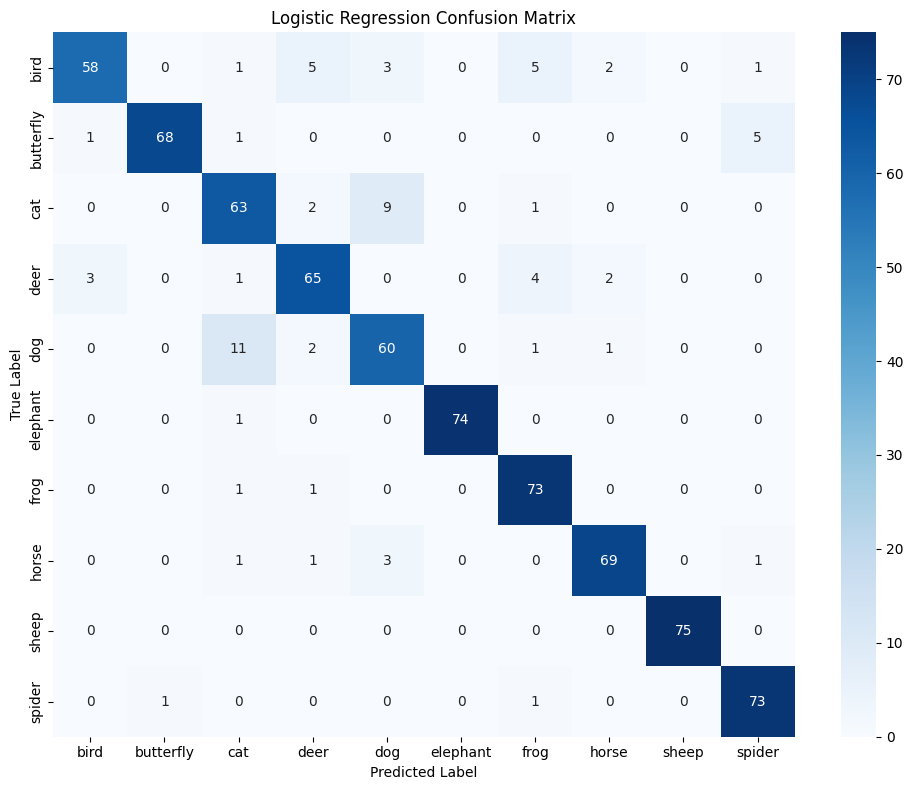

In [86]:
# graphs, confusion matrices and such 
# first logistic regression

cm_lr = confusion_matrix(y_val_res, lr_res.predict(X_val_res), labels=classes)

plt.figure(figsize=(10,8))
sns.heatmap(cm_lr, annot=True, fmt='d', xticklabels=classes, yticklabels=classes, cmap='Blues')
plt.title('Logistic Regression Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.tight_layout()
plt.show()

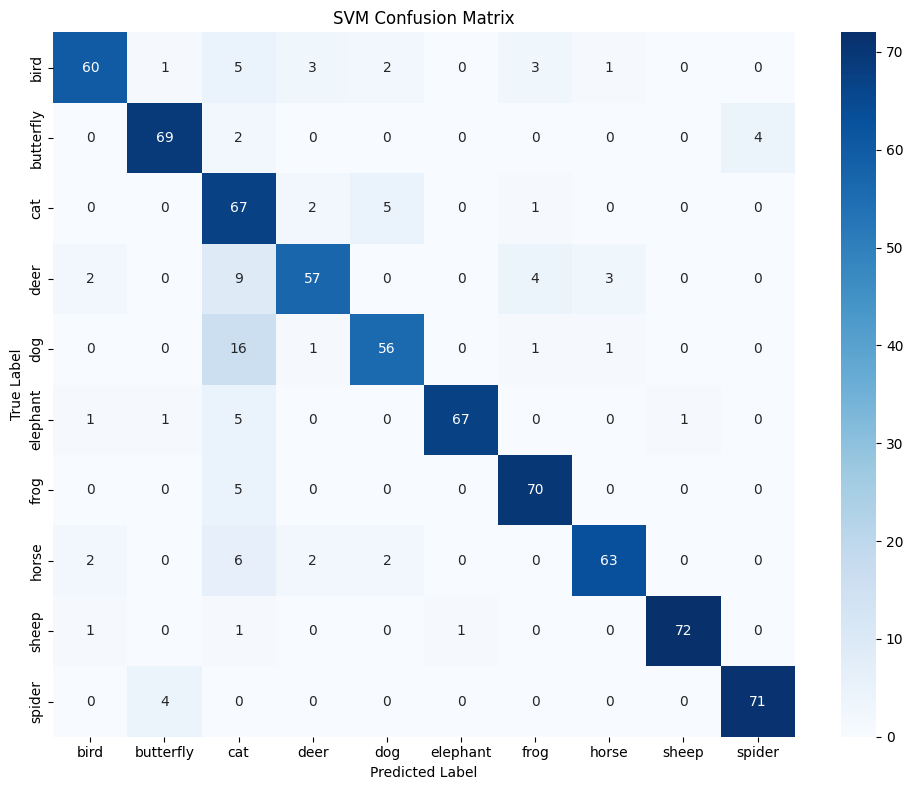

In [87]:
# SVM Confusion Matrix
cm_svm = confusion_matrix(y_val_res, svm_res.predict(X_val_res), labels=classes)

plt.figure(figsize=(10,8))
sns.heatmap(cm_svm, annot=True, fmt='d', xticklabels=classes, yticklabels=classes, cmap='Blues')
plt.title('SVM Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.tight_layout()
plt.show()

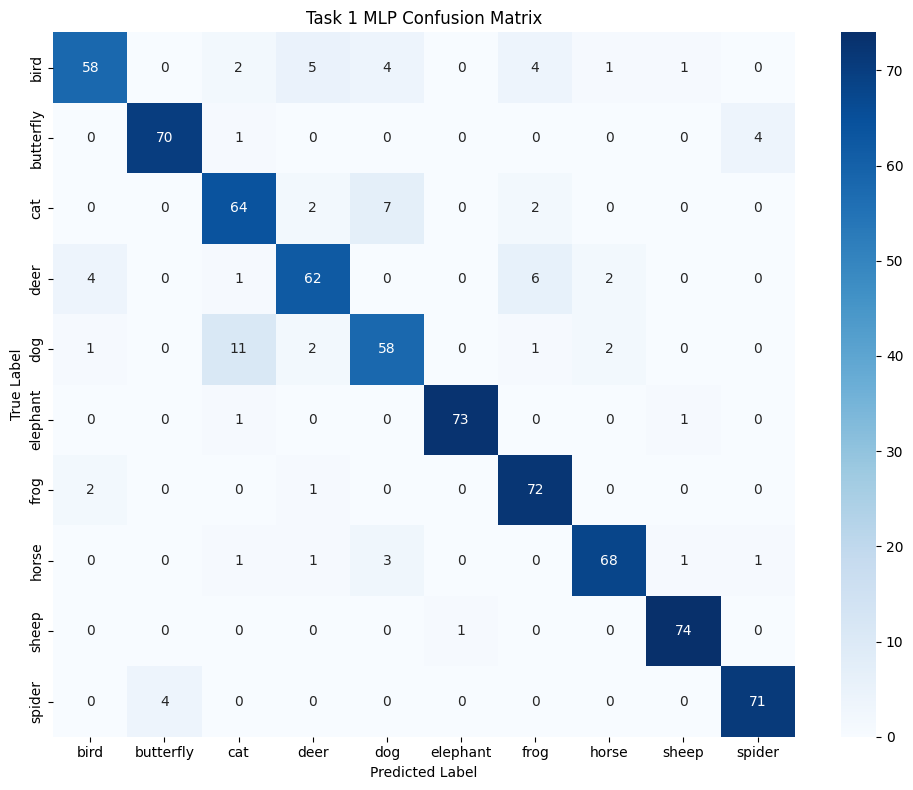

In [91]:
cm_mlp_t1 = confusion_matrix(y_val_enc, preds, labels=list(range(10)))
classes_encoded = le.classes_

plt.figure(figsize=(10,8))
sns.heatmap(cm_mlp_t1, annot=True, fmt='d', xticklabels=classes_encoded,
            yticklabels=classes_encoded, cmap='Blues')
plt.title('Task 1 MLP Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.tight_layout()
plt.show()


In [31]:
#### TASK 2
color_hist_t2 = pd.read_csv('task2_data/color_histogram.csv')
hog_pca_t2 = pd.read_csv('task2_data/hog_pca.csv')
additional_t2 = pd.read_csv('task2_data/additional_features.csv')

train_color_t2 = color_hist_t2[color_hist_t2['image_id'].str.startswith('train')].copy()
test_color_t2 = color_hist_t2[color_hist_t2['image_id'].str.startswith('test')].copy()

train_hog_t2 = hog_pca_t2[hog_pca_t2['image_id'].str.startswith('train')].copy()
test_hog_t2 = hog_pca_t2[hog_pca_t2['image_id'].str.startswith('test')].copy()

train_add_t2 = additional_t2[additional_t2['image_id'].str.startswith('train')].copy()
test_add_t2 = additional_t2[additional_t2['image_id'].str.startswith('test')].copy()

print(train_color_t2.shape, train_hog_t2.shape, train_add_t2.shape)

(417, 97) (417, 101) (417, 24)


In [32]:

train_df_t2 = train_color_t2.merge(train_hog_t2, on='image_id').merge(train_add_t2, on='image_id')
test_df_t2 = test_color_t2.merge(test_hog_t2, on='image_id').merge(test_add_t2, on='image_id')

# extract labels

train_df_t2['label'] = train_df_t2['image_id'].str.replace('train_', '').str.rsplit('_', n=1).str[0].str.replace('_', ' ')
print(train_df_t2['label'].value_counts())

label
American Goldfinch      42
Blue Jay                42
Herring Gull            42
House Sparrow           42
Red winged Blackbird    42
Ring billed Gull        42
Song Sparrow            42
Wilson Warbler          42
Yellow Warbler          42
Cardinal                39
Name: count, dtype: int64


In [33]:
feature_cols_t2 = [c for c in train_df_t2.columns if c not in ['image_id', 'label']]

X_t2 = train_df_t2[feature_cols_t2].values
y_t2 = train_df_t2['label'].values
X_test_t2 = test_df_t2[feature_cols_t2].values

scaler_t2 = StandardScaler()
X_t2_scaled = scaler_t2.fit_transform(X_t2)
X_test_t2_scaled = scaler_t2.transform(X_test_t2)

X_train_t2, X_val_t2, y_train_t2, y_val_t2 = train_test_split(
    X_t2_scaled, y_t2, test_size=0.2, random_state=42, stratify=y_t2)

# run all 3 models
knn_t2 = KNeighborsClassifier(n_neighbors=5)
knn_t2.fit(X_train_t2, y_train_t2)
print(f"KNN: {accuracy_score(y_val_t2, knn_t2.predict(X_val_t2)):.4f}")

lr_t2 = LogisticRegression(max_iter=1000, random_state=42)
lr_t2.fit(X_train_t2, y_train_t2)
print(f"LR: {accuracy_score(y_val_t2, lr_t2.predict(X_val_t2)):.4f}")

svm_t2 = SVC(kernel='rbf', C=10, gamma='scale', random_state=42)
svm_t2.fit(X_train_t2, y_train_t2)
print(f"SVM: {accuracy_score(y_val_t2, svm_t2.predict(X_val_t2)):.4f}")

KNN: 0.1310
LR: 0.2500
SVM: 0.3333


In [34]:
train_ids_t2, train_features_t2 = extract_features('task2_data/images/train', model, transform)

test_ids_t2, test_features_t2 = extract_features_flat('task2_data/images/test', model, transform)

print(f"Train: {len(train_ids_t2)}, Test: {len(test_ids_t2)}")

Extracting Task 2 training features...
Extracting Task 2 test features...
Train: 417, Test: 180


In [35]:
train_resnet_t2 = pd.DataFrame(train_features_t2, columns=[f'resnet_{i}' for i in range(2048)])
train_resnet_t2.insert(0, 'image_id', train_ids_t2)

test_resnet_t2 = pd.DataFrame(test_features_t2, columns=[f'resnet_{i}' for i in range(2048)])
test_resnet_t2.insert(0, 'image_id', test_ids_t2)

train_resnet_t2.to_csv('task2_data/resnet_train.csv', index=False)
test_resnet_t2.to_csv('task2_data/resnet_test.csv', index=False)

print(train_resnet_t2.shape, test_resnet_t2.shape)

(417, 2049) (180, 2049)


In [36]:
train_resnet_t2['label'] = train_resnet_t2['image_id'].str.rsplit('_', n=1).str[0].str.replace('_', ' ')
print(train_resnet_t2['label'].value_counts())

label
American Goldfinch      42
Blue Jay                42
Herring Gull            42
House Sparrow           42
Red winged Blackbird    42
Ring billed Gull        42
Song Sparrow            42
Wilson Warbler          42
Yellow Warbler          42
Cardinal                39
Name: count, dtype: int64


In [37]:
resnet_cols_t2 = [c for c in train_resnet_t2.columns if c.startswith('resnet_')]

X_res_t2 = train_resnet_t2[resnet_cols_t2].values
y_res_t2 = train_resnet_t2['label'].values
X_test_res_t2 = test_resnet_t2[resnet_cols_t2].values

scaler_res_t2 = StandardScaler()
X_res_t2_scaled = scaler_res_t2.fit_transform(X_res_t2)
X_test_res_t2_scaled = scaler_res_t2.transform(X_test_res_t2)

X_train_res_t2, X_val_res_t2, y_train_res_t2, y_val_res_t2 = train_test_split(
    X_res_t2_scaled, y_res_t2, test_size=0.2, random_state=42, stratify=y_res_t2)

knn_res_t2 = KNeighborsClassifier(n_neighbors=5)
knn_res_t2.fit(X_train_res_t2, y_train_res_t2)
print(f"KNN ResNet: {accuracy_score(y_val_res_t2, knn_res_t2.predict(X_val_res_t2)):.4f}")

lr_res_t2 = LogisticRegression(max_iter=1000, random_state=42)
lr_res_t2.fit(X_train_res_t2, y_train_res_t2)
print(f"LR ResNet: {accuracy_score(y_val_res_t2, lr_res_t2.predict(X_val_res_t2)):.4f}")

svm_res_t2 = SVC(kernel='rbf', C=10, gamma='scale', random_state=42)
svm_res_t2.fit(X_train_res_t2, y_train_res_t2)
print(f"SVM ResNet: {accuracy_score(y_val_res_t2, svm_res_t2.predict(X_val_res_t2)):.4f}")

KNN ResNet: 0.6071
LR ResNet: 0.8452
SVM ResNet: 0.7976


In [81]:
# Linear SVM Task 2
lsvm_t2 = LinearSVC(C=1, max_iter=3000, random_state=42)
lsvm_t2.fit(X_train_res_t2, y_train_res_t2)
y_pred_lsvm_t2 = lsvm_t2.predict(X_val_res_t2)
print(f"Linear SVM Task 2: {accuracy_score(y_val_res_t2, y_pred_lsvm_t2):.4f}")


Linear SVM Task 2: 0.8452


In [67]:
# basic neural network experiment
le2 = LabelEncoder()
y_train_enc2 = le2.fit_transform(y_train_res_t2)
y_val_enc2 = le2.transform(y_val_res_t2)

X_train_t2 = torch.FloatTensor(X_train_res_t2)
y_train_t2t = torch.LongTensor(y_train_enc2)
X_val_t2 = torch.FloatTensor(X_val_res_t2)

model_mlp2 = MLP()
optimizer2 = torch.optim.Adam(model_mlp2.parameters(), lr=0.0001)

for epoch in range(200):
    model_mlp2.train()
    optimizer2.zero_grad()
    out = model_mlp2(X_train_t2)
    loss = criterion(out, y_train_t2t)
    loss.backward()
    optimizer2.step()

model_mlp2.eval()
with torch.no_grad():
    preds2 = model_mlp2(X_val_t2).argmax(dim=1).numpy()
print(f"MLP Task 2: {accuracy_score(y_val_enc2, preds2):.4f}")

MLP Task 2: 0.8571


In [70]:
# dataset is small, try combining features of resnet and csv
feature_cols_t2_basic = [c for c in train_df_t2.columns 
                          if c not in ['image_id', 'image_id_short', 'label']]

train_df_t2['image_id_short'] = train_df_t2['image_id'].str.replace('train_', '')
test_df_t2['image_id_short'] = test_df_t2['image_id'].str.replace('test_', '')

train_resnet_t2['image_id_short'] = train_resnet_t2['image_id']
test_resnet_t2['image_id_short'] = test_resnet_t2['image_id'].str.replace('test_', '')

train_combined_t2 = train_resnet_t2.merge(
    train_df_t2[['image_id_short'] + feature_cols_t2_basic], on='image_id_short')

print(train_combined_t2.shape)

(417, 2270)


In [71]:
combined_cols_t2 = [c for c in train_combined_t2.columns 
                    if c not in ['image_id', 'image_id_short', 'label']]

X_comb_t2 = train_combined_t2[combined_cols_t2].values
y_comb_t2 = train_combined_t2['label'].values

scaler_comb_t2 = StandardScaler()
X_comb_t2_scaled = scaler_comb_t2.fit_transform(X_comb_t2)

X_train_comb_t2, X_val_comb_t2, y_train_comb_t2, y_val_comb_t2 = train_test_split(
    X_comb_t2_scaled, y_comb_t2, test_size=0.2, random_state=42, stratify=y_comb_t2)

svm_comb_t2 = SVC(kernel='rbf', C=10, gamma='scale', random_state=42)
svm_comb_t2.fit(X_train_comb_t2, y_train_comb_t2)
print(f"SVM Combined Task 2: {accuracy_score(y_val_comb_t2, svm_comb_t2.predict(X_val_comb_t2)):.4f}")
print(f"SVM ResNet only Task 2: 0.7976")

SVM Combined Task 2: 0.7857
SVM ResNet only Task 2: 0.7976


In [74]:
# try gridsearch for SVM resnet
from sklearn.model_selection import GridSearchCV
param_grid = {'C': [0.1, 1, 10, 100], 'gamma': ['scale', 'auto']}
grid_search_t2 = GridSearchCV(SVC(kernel='rbf', random_state=42),
                               param_grid, cv=5, scoring='accuracy')
grid_search_t2.fit(X_res_t2_scaled, y_res_t2)

print(f"Best params: {grid_search_t2.best_params_}")
print(f"Best CV accuracy: {grid_search_t2.best_score_:.4f}")

Best params: {'C': 10, 'gamma': 'scale'}
Best CV accuracy: 0.8033


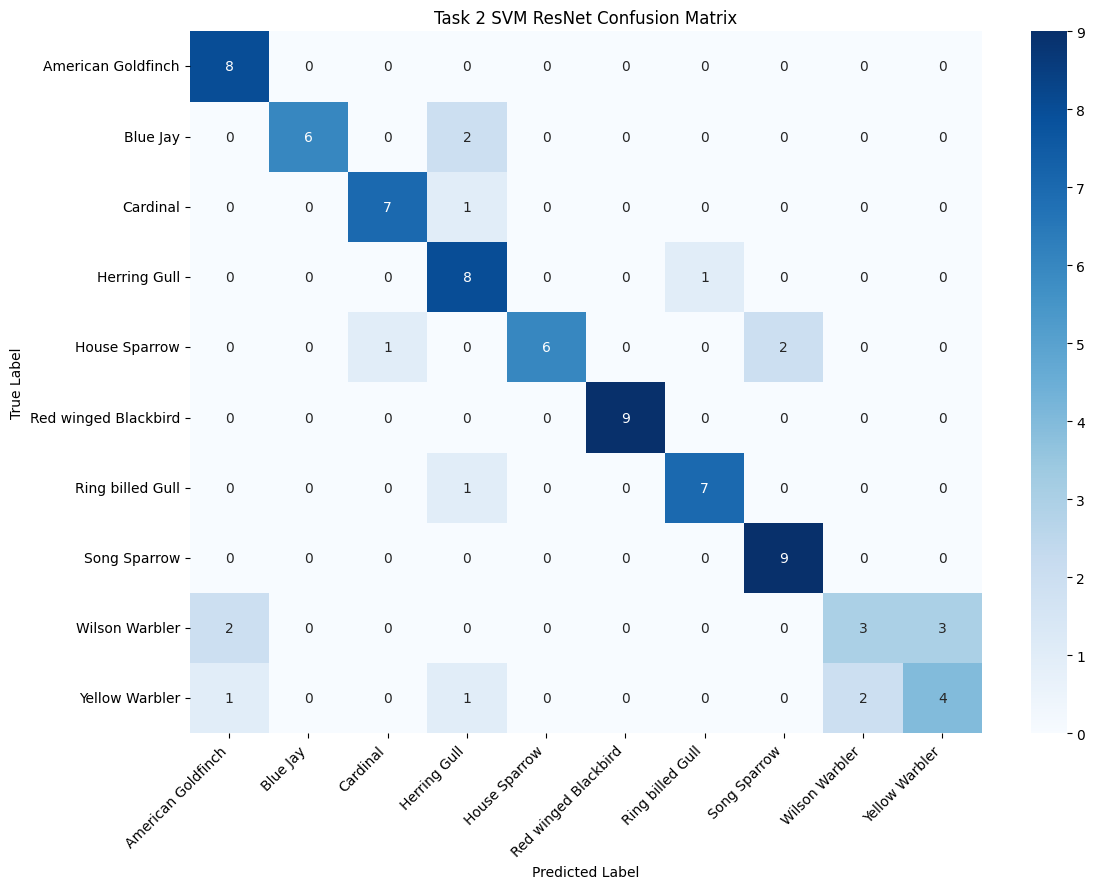

In [88]:
classes_t2 = sorted(train_resnet_t2['label'].unique())
y_pred_svm_res_t2 = svm_res_t2.predict(X_val_res_t2)

cm_svm_res_t2 = confusion_matrix(y_val_res_t2, y_pred_svm_res_t2, labels=classes_t2)

plt.figure(figsize=(12, 9))
sns.heatmap(cm_svm_res_t2, annot=True, fmt='d', xticklabels=classes_t2, 
            yticklabels=classes_t2, cmap='Blues')
plt.title('Task 2 SVM ResNet Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

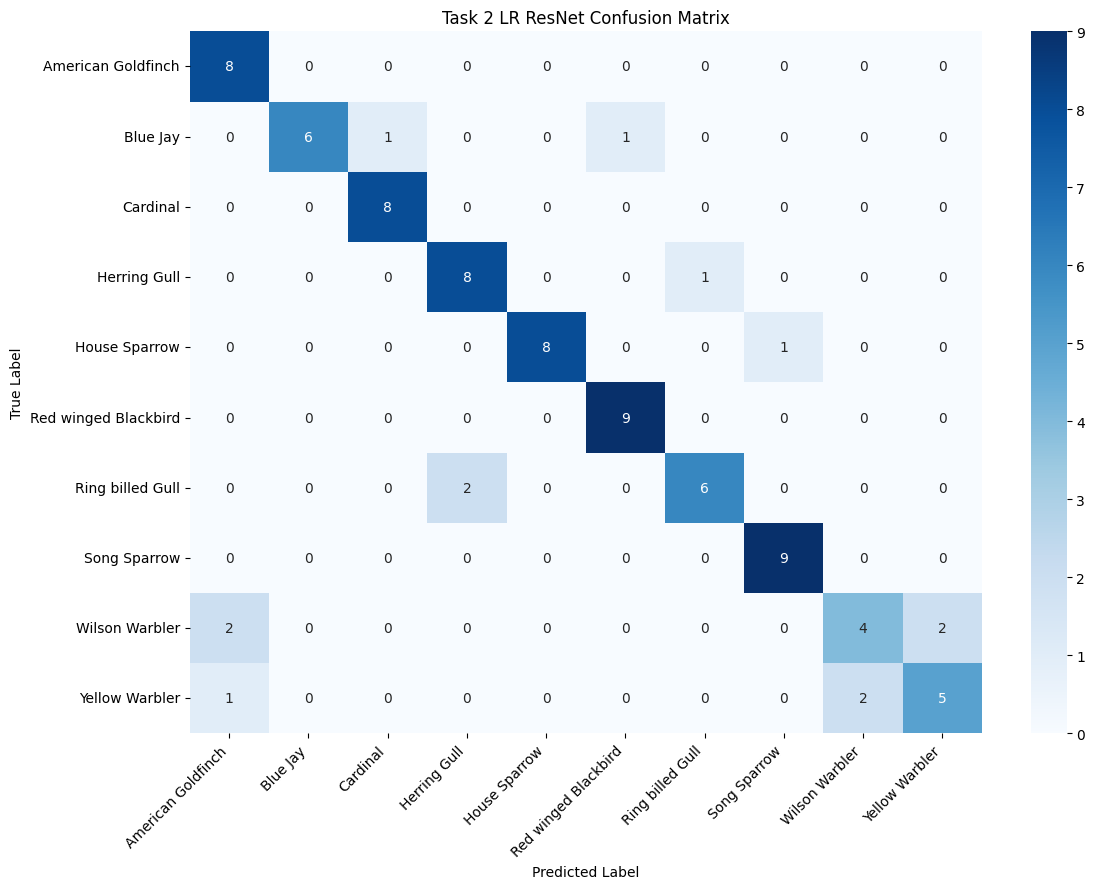

In [89]:
y_pred_lr_res_t2 = lr_res_t2.predict(X_val_res_t2)
cm_lr_res_t2 = confusion_matrix(y_val_res_t2, y_pred_lr_res_t2, labels=classes_t2)

plt.figure(figsize=(12, 9))
sns.heatmap(cm_lr_res_t2, annot=True, fmt='d', xticklabels=classes_t2,
            yticklabels=classes_t2, cmap='Blues')
plt.title('Task 2 LR ResNet Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

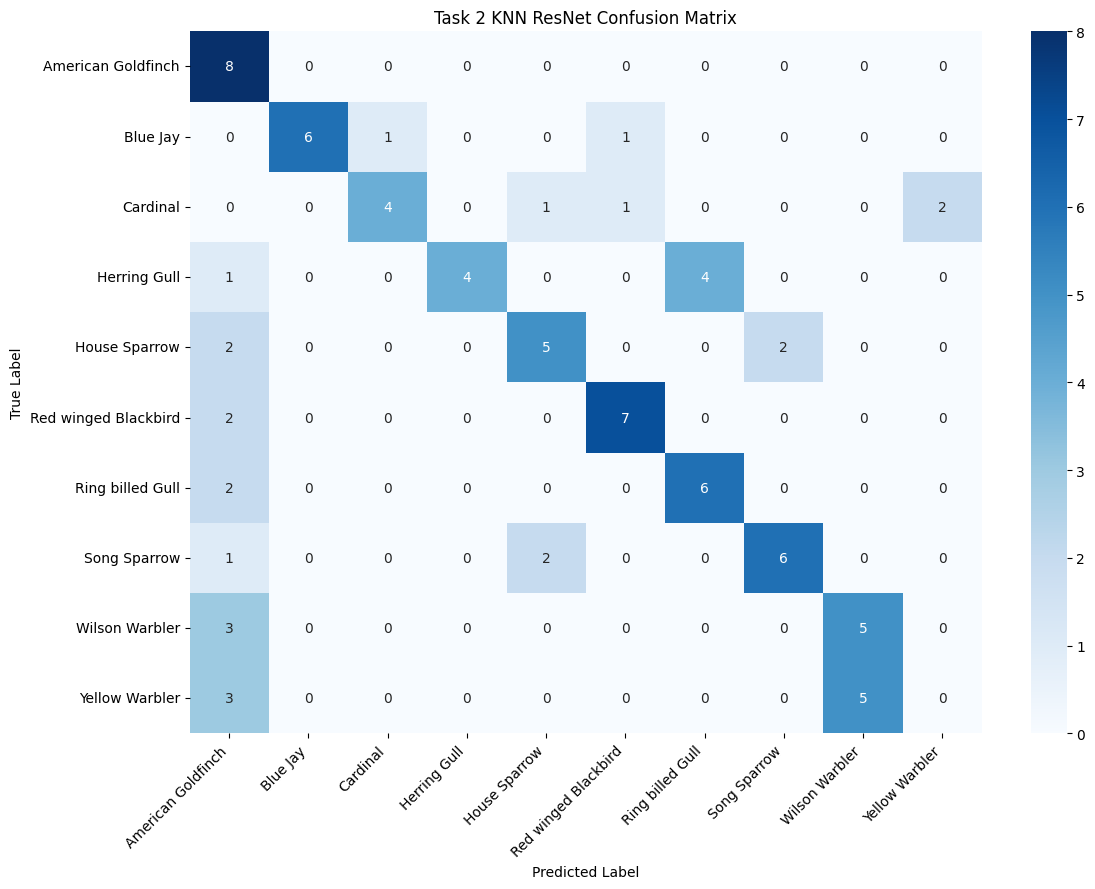

In [90]:
# KNN confusion matrix
y_pred_knn_res_t2 = knn_res_t2.predict(X_val_res_t2)
cm_knn_res_t2 = confusion_matrix(y_val_res_t2, y_pred_knn_res_t2, labels=classes_t2)

plt.figure(figsize=(12, 9))
sns.heatmap(cm_knn_res_t2, annot=True, fmt='d', xticklabels=classes_t2,
            yticklabels=classes_t2, cmap='Blues')
plt.title('Task 2 KNN ResNet Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


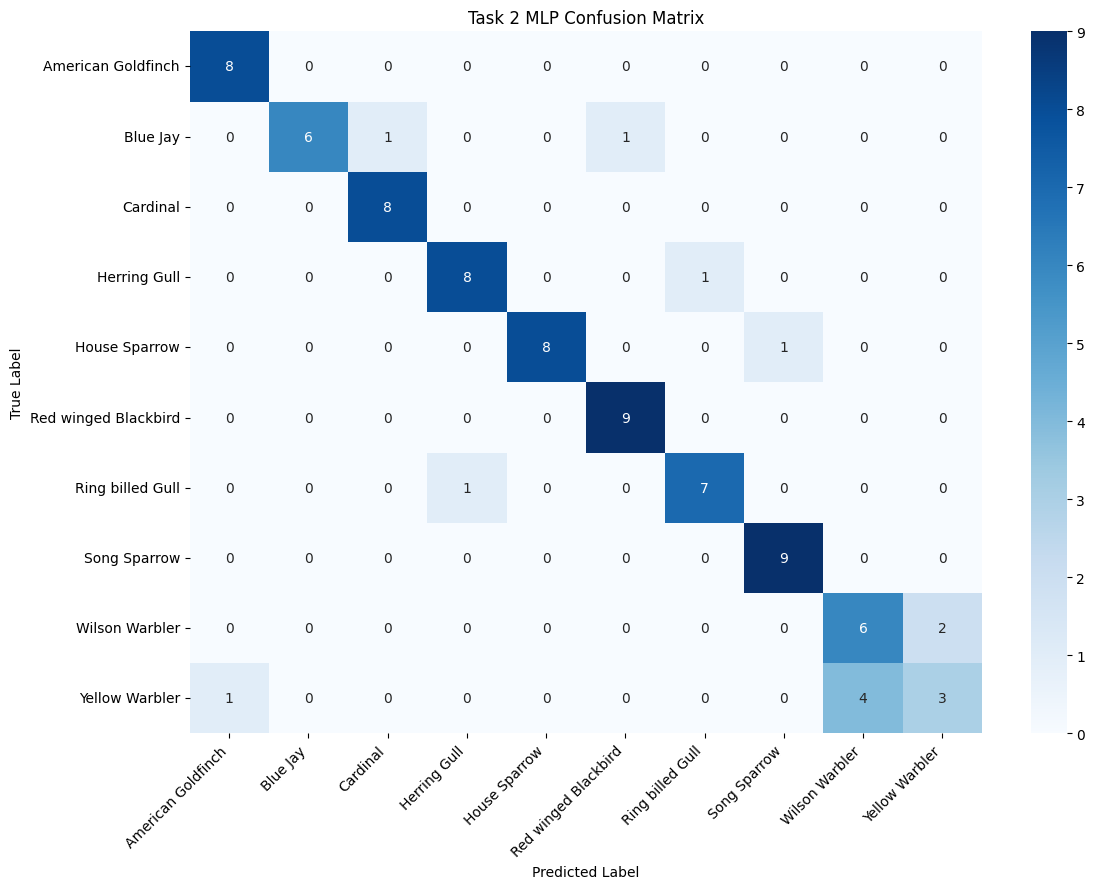

In [92]:
# Task 2 MLP confusion matrix
cm_mlp_t2 = confusion_matrix(y_val_enc2, preds2, labels=list(range(10)))
classes_encoded_t2 = le2.classes_

plt.figure(figsize=(12,9))
sns.heatmap(cm_mlp_t2, annot=True, fmt='d', xticklabels=classes_encoded_t2,
            yticklabels=classes_encoded_t2, cmap='Blues')
plt.title('Task 2 MLP Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [83]:
lsvm_result_t2 = {
    "Model": "Linear SVM (ResNet50)",
    "Accuracy": accuracy_score(y_val_res_t2, y_pred_lsvm_t2),
    "Balanced Accuracy": balanced_accuracy_score(y_val_res_t2, y_pred_lsvm_t2),
    "Macro Precision": precision_score(y_val_res_t2, y_pred_lsvm_t2, average="macro", zero_division=0),
    "Macro Recall/Sensitivity": recall_score(y_val_res_t2, y_pred_lsvm_t2, average="macro", zero_division=0),
    "Macro Specificity": macro_specificity_score(y_val_res_t2, y_pred_lsvm_t2),
    "Macro F1-score": f1_score(y_val_res_t2, y_pred_lsvm_t2, average="macro", zero_division=0),
    "Weighted F1-score": f1_score(y_val_res_t2, y_pred_lsvm_t2, average="weighted", zero_division=0)
}

mlp_result_t2 = {
    "Model": "MLP (ResNet50)",
    "Accuracy": accuracy_score(y_val_enc2, preds2),
    "Balanced Accuracy": balanced_accuracy_score(y_val_enc2, preds2),
    "Macro Precision": precision_score(y_val_enc2, preds2, average="macro", zero_division=0),
    "Macro Recall/Sensitivity": recall_score(y_val_enc2, preds2, average="macro", zero_division=0),
    "Macro Specificity": macro_specificity_score(y_val_enc2, preds2),
    "Macro F1-score": f1_score(y_val_enc2, preds2, average="macro", zero_division=0),
    "Weighted F1-score": f1_score(y_val_enc2, preds2, average="weighted", zero_division=0)
}

results_2 = []
results_2.append(evaluate_model("KNN (ResNet50)", knn_res_t2, X_val_res_t2, y_val_res_t2))
results_2.append(evaluate_model("Logistic Regression (ResNet50)", lr_res_t2, X_val_res_t2, y_val_res_t2))
results_2.append(evaluate_model("SVM RBF - Grid Search (ResNet50)", svm_res_t2, X_val_res_t2, y_val_res_t2))
results_2.append(lsvm_result_t2)
results_2.append(mlp_result_t2)

results_df_2 = pd.DataFrame(results_2)
results_df_2

,Model,Accuracy,Balanced Accuracy,Macro Precision,Macro Recall/Sensitivity,Macro Specificity,Macro F1-score,Weighted F1-score
0,KNN (ResNet50),0.607143,0.606944,0.641641,0.606944,0.956456,0.591536,0.595359
1,Logistic Regression (ResNet50),0.845238,0.840278,0.845426,0.840278,0.982825,0.835654,0.839647
2,SVM RBF - Grid Search (ResNet50),0.797619,0.793056,0.808227,0.793056,0.977509,0.787139,0.790457
3,Linear SVM (ResNet50),0.845238,0.841667,0.847648,0.841667,0.982860,0.838502,0.842755
4,MLP (ResNet50),0.857143,0.852778,0.854167,0.852778,0.984158,0.846750,0.850772


In [84]:
results_df_rounded_2 = results_df_2.copy()

metric_cols = [
    "Accuracy",
    "Balanced Accuracy",
    "Macro Precision",
    "Macro Recall/Sensitivity",
    "Macro Specificity",
    "Macro F1-score",
    "Weighted F1-score"
]

results_df_rounded_2[metric_cols] = results_df_rounded_2[metric_cols].round(4)

results_df_rounded_2

,Model,Accuracy,Balanced Accuracy,Macro Precision,Macro Recall/Sensitivity,Macro Specificity,Macro F1-score,Weighted F1-score
0,KNN (ResNet50),0.6071,0.6069,0.6416,0.6069,0.9565,0.5915,0.5954
1,Logistic Regression (ResNet50),0.8452,0.8403,0.8454,0.8403,0.9828,0.8357,0.8396
2,SVM RBF - Grid Search (ResNet50),0.7976,0.7931,0.8082,0.7931,0.9775,0.7871,0.7905
3,Linear SVM (ResNet50),0.8452,0.8417,0.8476,0.8417,0.9829,0.8385,0.8428
4,MLP (ResNet50),0.8571,0.8528,0.8542,0.8528,0.9842,0.8468,0.8508


In [41]:
## kaggle subnmission
train_meta2 = pd.read_csv('task2_data/train_metadata.csv')
print(train_meta2[['class_id', 'class_name']].drop_duplicates().sort_values('class_id'))

     class_id            class_name
0           0    American_Goldfinch
42          1              Blue_Jay
84          2              Cardinal
123         3          Herring_Gull
165         4         House_Sparrow
207         5  Red_winged_Blackbird
249         6      Ring_billed_Gull
291         7          Song_Sparrow
333         8        Wilson_Warbler
375         9        Yellow_Warbler


In [42]:
print(np.unique(y_train_res_t2))

['American Goldfinch' 'Blue Jay' 'Cardinal' 'Herring Gull' 'House Sparrow'
 'Red winged Blackbird' 'Ring billed Gull' 'Song Sparrow' 'Wilson Warbler'
 'Yellow Warbler']


In [43]:
name_to_class_id = {k.replace('_', ' '): v 
                    for k, v in zip(train_meta2['class_name'], train_meta2['class_id'])}

test_preds = lr_res_t2.predict(X_test_res_t2_scaled)
test_pred_ids = [name_to_class_id[p] for p in test_preds]

submission = pd.DataFrame({
    'image_id': test_resnet_t2['image_id'],
    'class_id': test_pred_ids
})
print(submission.head(10))
print(submission.shape)

submission.to_csv('submissions/task2_submission.csv', index=False)
print("Saved.")

    image_id  class_id
0  test_0000         9
1  test_0001         2
2  test_0002         0
3  test_0003         2
4  test_0004         0
5  test_0005         2
6  test_0006         6
7  test_0007         6
8  test_0008         3
9  test_0009         1
(180, 2)
Saved.
